# Stock risk report

Risk report for one stock, using `ohlc_hw_cleaned` from `01_data_cleaning.ipynb`. It can be run by hand or through papermill (`03_run_all_stocks.py` does that for every ticker).

Returns and drawdown use the adjusted close. Volatility, Sharpe and the daily stats use daily log returns, with 252 trading days a year and a 2% risk-free rate.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from matplotlib.ticker import PercentFormatter

TRADING_DAYS = 252
RED, GREEN, GRAY, BLUE = '#d1495b', '#2e8b57', '#a0a0a0', '#1d3557'

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # local copy of the database with ohlc_hw_cleaned

In [3]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "../../data/data.db"


## Data loading

In [4]:
if not Path(db_path).exists():
    raise FileNotFoundError(f'{db_path} not found, run 01_data_cleaning.ipynb first')
if start_date > end_date:
    raise ValueError(f'start_date {start_date} is after end_date {end_date}')

conn = sqlite3.connect(db_path)
known = conn.execute('SELECT 1 FROM ohlc_hw_cleaned WHERE ticker = ? LIMIT 1', (ticker,)).fetchone()
df = pd.read_sql_query('SELECT ts, open, high, low, close, adj_close, volume FROM ohlc_hw_cleaned '
                       'WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts',
                       conn, params=(ticker, start_date, end_date), parse_dates=['ts'], index_col='ts')
conn.close()

if known is None:
    raise ValueError(f'{ticker} is not in ohlc_hw_cleaned')
# 20 returns need 21 prices
if len(df) < 21:
    raise ValueError(f'not enough history: {ticker} has {len(df)} prices between {start_date} and {end_date}, need 21')

first_date, last_date = df.index.min(), df.index.max()
print(f'{ticker} from {start_date} to {end_date}: {len(df)} trading days')
print(f'first observation {first_date:%Y-%m-%d}, last observation {last_date:%Y-%m-%d}')
short_history = (pd.Timestamp(end_date) - last_date).days > 7 or (first_date - pd.Timestamp(start_date)).days > 7
if short_history:
    print(f'{ticker} data does not cover the whole window. Nothing is extrapolated, so keep that in mind '
          'when comparing it with other reports.')
display(df.head())
display(df.tail())

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
first observation 2024-06-03, last observation 2024-10-18
AAPL data does not cover the whole window. Nothing is extrapolated, so keep that in mind when comparing it with other reports.


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539
2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445
2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785
2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753
2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


In [5]:
prices = df[['open', 'high', 'low', 'close', 'adj_close']]
problems = {
    'missing or infinite price': (~np.isfinite(prices)).any(axis=1).sum(),
    'zero or negative price': (prices <= 0).any(axis=1).sum(),
    'open/close outside [low, high]': ((df['high'] < df[['open', 'close']].max(axis=1))
                                       | (df['low'] > df[['open', 'close']].min(axis=1))).sum(),
    'negative volume': (df['volume'] < 0).sum(),
    'duplicate dates': df.index.duplicated().sum(),
}
if any(problems.values()):
    raise ValueError(f'bad input data: {problems}')

## Risk metrics

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns (the first one is NaN, not 0)."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility (NaN until the window is full)."""
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak. Its .min() is the maximum drawdown."""
    running_max = prices.cummax()
    return (prices - running_max) / running_max


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio (NaN with fewer than 2 returns or zero volatility)."""
    returns = returns.dropna()
    std = returns.std()
    if len(returns) < 2 or not std > 0:
        return np.nan
    return (returns.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS))

In [7]:
df['log_return'] = calculate_returns(df['adj_close'])
df['volatility'] = calculate_volatility(df['log_return'])
df['ma_50'] = df['adj_close'].rolling(50).mean()
df['drawdown'] = calculate_max_drawdown(df['adj_close'])

returns = df['log_return'].dropna()
mean_vol = df['volatility'].mean()
sharpe = calculate_sharpe_ratio(returns)
max_dd = df['drawdown'].min()
max_dd_date = df['drawdown'].idxmin()

display(df[['adj_close', 'log_return', 'volatility', 'ma_50', 'drawdown']].iloc[18:22])
print(f'{len(returns)} daily log returns, mean {returns.mean():.4%}, std {returns.std():.4%}')
print(f'20-day volatility from {df["volatility"].first_valid_index():%Y-%m-%d}, mean {mean_vol:.2%}')
print('Sharpe ratio:', 'N/A' if pd.isna(sharpe) else round(sharpe, 2))
print(f'max drawdown {max_dd:.2%} on {max_dd_date:%Y-%m-%d}')
if df['ma_50'].isna().all():
    print(f'no 50-day moving average: only {len(df)} prices')

,adj_close,log_return,volatility,ma_50,drawdown
ts,,,,,
2024-06-28,210.38,-0.016359,NaN,NaN,-0.027909
2024-07-01,216.50,0.028675,NaN,NaN,0.000000
2024-07-02,220.02,0.016128,0.335958,NaN,0.000000
2024-07-03,221.29,0.005756,0.335513,NaN,0.000000


96 daily log returns, mean 0.2007%, std 1.6035%
20-day volatility from 2024-07-02, mean 24.08%
Sharpe ratio: 1.91
max drawdown -11.75% on 2024-08-06


## Visualization

The price line is red when the 20-day volatility is above its mean for the period, green otherwise, and gray before the first volatility value exists. The mean uses the whole period, so the colors only describe the past.

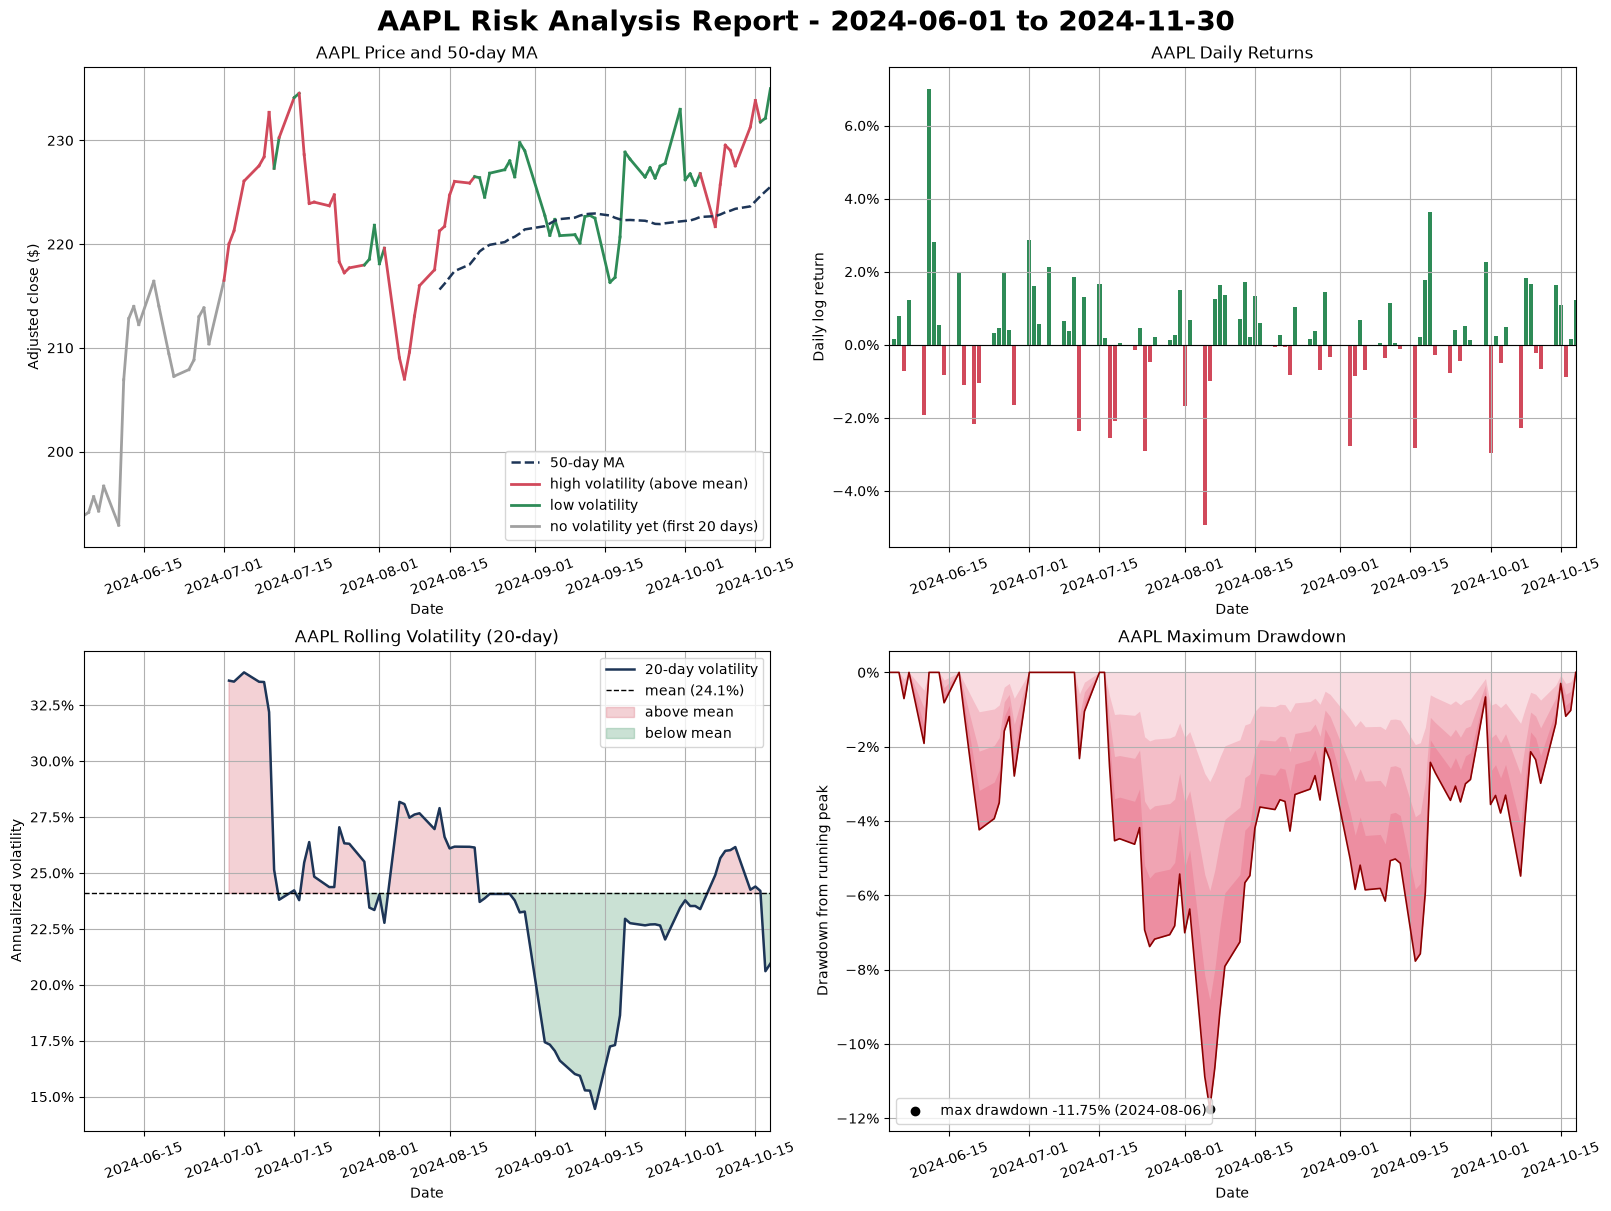

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=20, fontweight='bold')

# price, one segment at a time so each can get its own color
ax = axes[0, 0]
for i in range(1, len(df)):
    vol = df['volatility'].iloc[i]
    color = GRAY if pd.isna(vol) else RED if vol > mean_vol else GREEN
    ax.plot(df.index[i - 1:i + 1], df['adj_close'].iloc[i - 1:i + 1], color=color, lw=2)
ax.plot(df.index, df['ma_50'], color=BLUE, lw=1.8, ls='--', label='50-day MA')
ax.plot([], [], color=RED, lw=2, label='high volatility (above mean)')
ax.plot([], [], color=GREEN, lw=2, label='low volatility')
ax.plot([], [], color=GRAY, lw=2, label='no volatility yet (first 20 days)')
ax.legend()
ax.set(title=f'{ticker} Price and 50-day MA', xlabel='Date', ylabel='Adjusted close ($)')

ax = axes[0, 1]
ax.bar(df.index, df['log_return'] * 100, color=np.where(df['log_return'] >= 0, GREEN, RED))
ax.axhline(0, color='black', lw=0.8)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=1))
ax.set(title=f'{ticker} Daily Returns', xlabel='Date', ylabel='Daily log return')

ax = axes[1, 0]
vol_pct = df['volatility'] * 100
ax.plot(df.index, vol_pct, color=BLUE, lw=1.8, label='20-day volatility')
ax.axhline(mean_vol * 100, color='black', ls='--', lw=1, label=f'mean ({mean_vol:.1%})')
ax.fill_between(df.index, vol_pct, mean_vol * 100, where=vol_pct > mean_vol * 100, interpolate=True,
                color=RED, alpha=0.25, label='above mean')
ax.fill_between(df.index, vol_pct, mean_vol * 100, where=vol_pct <= mean_vol * 100, interpolate=True,
                color=GREEN, alpha=0.25, label='below mean')
ax.yaxis.set_major_formatter(PercentFormatter(decimals=1))
ax.legend()
ax.set(title=f'{ticker} Rolling Volatility (20-day)', xlabel='Date', ylabel='Annualized volatility')

# drawdown: a few transparent layers make it darker near the bottom
ax = axes[1, 1]
dd_pct = df['drawdown'] * 100
for frac in [0, 0.25, 0.5, 0.75]:
    ax.fill_between(df.index, dd_pct, dd_pct * frac, color='crimson', alpha=0.15, lw=0)
ax.plot(df.index, dd_pct, color='darkred', lw=1.2)
ax.scatter(max_dd_date, max_dd * 100, color='black', label=f'max drawdown {max_dd:.2%} ({max_dd_date:%Y-%m-%d})')
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.legend(loc='lower left')
ax.set(title=f'{ticker} Maximum Drawdown', xlabel='Date', ylabel='Drawdown from running peak')

for ax in axes.flat:
    ax.grid(True)
    ax.set_xlim(df.index[0], df.index[-1])
    ax.tick_params(axis='x', labelrotation=20)
plt.show()

## Summary statistics

Total return is last / first adjusted close - 1. Annualized return is `exp(sum(log returns) * 252 / n) - 1`, with `n` the number of returns. Annualized volatility is the std of all daily log returns times sqrt(252), which is not the same as the mean of the rolling volatility. Best/worst day and the up/down averages are log returns, and positive days are counted out of all `n` returns.

In [9]:
n = len(returns)
metrics = {
    'Total Return': df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1,
    'Annualized Return': np.exp(returns.sum() * TRADING_DAYS / n) - 1,
    'Annualized Volatility': returns.std() * np.sqrt(TRADING_DAYS),
    'Sharpe Ratio': sharpe,
    'Maximum Drawdown': max_dd,
    'Best Day': returns.max(),
    'Worst Day': returns.min(),
    'Positive Days': (returns > 0).sum() / n,
    'Average Up Day': returns[returns > 0].mean(),
    'Average Down Day': returns[returns < 0].mean(),
}

print(f'{"Metric":<25} {"Value":>8}')
print(f'{"-" * 24}  {"-" * 8}')
for name, value in metrics.items():
    if pd.isna(value):
        text = 'N/A'
    elif name == 'Sharpe Ratio':
        text = f'{value:.2f}'
    elif name == 'Annualized Volatility':
        text = f'{value:.2%}'
    elif name == 'Positive Days':
        text = f'{value:.1%}'
    else:
        text = f'{value:+.2%}'
    print(f'{name:<25} {text:>8}')
if short_history:
    print(f'\nonly covers {first_date:%Y-%m-%d} to {last_date:%Y-%m-%d}')

Metric                       Value
------------------------  --------
Total Return               +21.25%
Annualized Return          +65.84%
Annualized Volatility       25.45%
Sharpe Ratio                  1.91
Maximum Drawdown           -11.75%
Best Day                    +7.01%
Worst Day                   -4.94%
Positive Days                62.5%
Average Up Day              +1.09%
Average Down Day            -1.28%

only covers 2024-06-03 to 2024-10-18


The numbers below are saved in the notebook with scrapbook, so `03_run_all_stocks.py` can read them back.

In [10]:
sb.glue('report_metrics', {
    'first_date': f'{first_date:%Y-%m-%d}',
    'last_date': f'{last_date:%Y-%m-%d}',
    'trading_days': len(df),
    'avg_daily_return': returns.mean(),
    'avg_volatility': mean_vol,
    'max_drawdown': max_dd,
    'sharpe_ratio': sharpe,
    'total_return': metrics['Total Return'],
})